In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

In [3]:
import kagglehub
path = kagglehub.dataset_download("nicapotato/womens-ecommerce-clothing-reviews")

print("File dirctory of dataset", path)

# Check file location
import os
for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        print(os.path.join(dirname, filename))

Using Colab cache for faster access to the 'womens-ecommerce-clothing-reviews' dataset.
File dirctory of dataset /kaggle/input/womens-ecommerce-clothing-reviews
/kaggle/input/womens-ecommerce-clothing-reviews/Womens Clothing E-Commerce Reviews.csv


In [4]:
# load file
df = pd.read_csv("/kaggle/input/womens-ecommerce-clothing-reviews/Womens Clothing E-Commerce Reviews.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


## 1. Understand the data

+ Shape, columns, data types, duplicates and data quality.

In [5]:
# Check shape of data
print("Shape of Dataset:", df.shape)

Shape of Dataset: (23486, 11)


In [6]:
# check first five row of data
display(df.head())

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [7]:
# check information of data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB


In [8]:
# check duplicae value
df.duplicated().sum()

np.int64(0)

In [9]:
# check null value
df.isnull().sum().sort_values(ascending=False)

,0
Title,3810
Review Text,845
Department Name,14
Class Name,14
Division Name,14
Unnamed: 0,0
Clothing ID,0
Age,0
Rating,0
Recommended IND,0


+  **Unnamed: 0** this column is simply an old DataFrame index, it has no predictive value. We can drop it.
+  **Review Text:** Remove null values this is our main input feature for NLP. If the review text is missing, we cannot perform sentiment analysis on that record. Therefore, remove those rows.
+ **Department Name, Class Name, Division Name:** These are categorical columns. We can replace missing values with "Unknown" instead of deleting records.

In [10]:
# Before dropping it verify whether Unnamed: 0 is really an index
df.sample(10)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
10928,10928,1086,33,Quality issues,I wanted to love this dress. i've been looking...,3,0,0,General,Dresses,Dresses
19078,19078,850,58,Boxy,This top is too boxy and has too much going on...,2,0,0,General,Tops,Blouses
1412,1412,442,32,NaN,Very pretty but also very roomy. i'm using it ...,4,1,0,Initmates,Intimate,Swim
19613,19613,479,40,NaN,Love these shorts! fit true to size and the ma...,5,1,0,General,Bottoms,Shorts
10188,10188,831,38,Happy birthday to me!,Another winner for me! this top drapes wonderf...,5,1,2,General,Tops,Blouses
965,965,1140,36,NaN,This skirt is not what i was expecting at all....,3,0,3,General Petite,Trend,Trend
14495,14495,909,49,Returned,"The fit was not flattering at all, but the wor...",1,0,0,General,Tops,Fine gauge
2227,2227,867,40,NaN,I love this tee. really comfortable and super ...,4,1,0,General Petite,Tops,Knits
21672,21672,1008,33,Love maeve skirts!,"Again, maeve knocks it out of the park with th...",5,1,0,General Petite,Bottoms,Skirts
2727,2727,1094,41,So beautiful!,Love the way this feels ? epic and flowy and f...,5,1,0,General Petite,Dresses,Dresses


In [11]:
# Drop Unname: 0 and null value columns from Review text
df.drop(["Unnamed: 0"], axis=1, inplace=True)
df.dropna(subset=["Review Text"], inplace=True)

# Department Name, Class Name, Division Name null value fill with "Unknown"
cat_col = ["Department Name", "Class Name", "Division Name"]

for col in cat_col:
    df[col].fillna("Unknown", inplace=True)

# Fill missing Title values
df['Title'] = df['Title'].fillna('')

/tmp/ipykernel_4286/3836600719.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna("Unknown", inplace=True)


In [12]:
# Shape after clean data
df.shape

(22641, 10)

In [13]:
df[["Title", "Division Name","Department Name","Class Name"]].describe(include=["O"]).T.drop("count",axis=1)

,unique,top,freq
Title,13993,,2966
Division Name,4,General,13365
Department Name,7,Tops,10048
Class Name,21,Dresses,6145


In [14]:
df['Full_Review'] = df['Title'] + ' ' + df['Review Text']

,count
Rating,
5,12540
4,4908
3,2823
2,1549
1,821


/tmp/ipykernel_4286/4254500654.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Rating", data=df, palette="viridis")


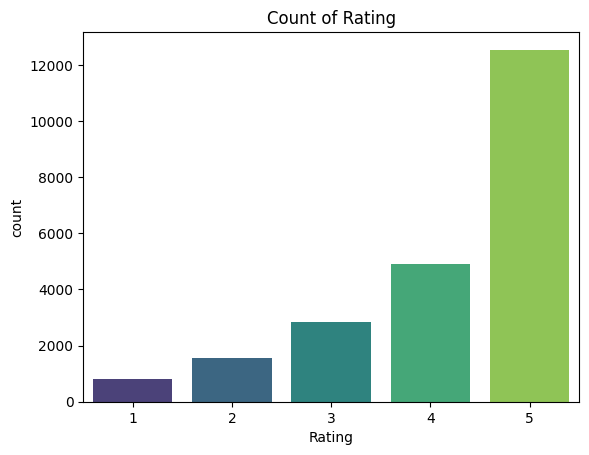

In [15]:
# Count plot of rating
display(df["Rating"].value_counts())
sns.countplot(x="Rating", data=df, palette="viridis")
plt.xlabel("Rating")
plt.title("Count of Rating")
plt.show()

In [16]:
# Convert rating into three categories
def rating_category(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["Rating_Category"] = df["Rating"].apply(rating_category)



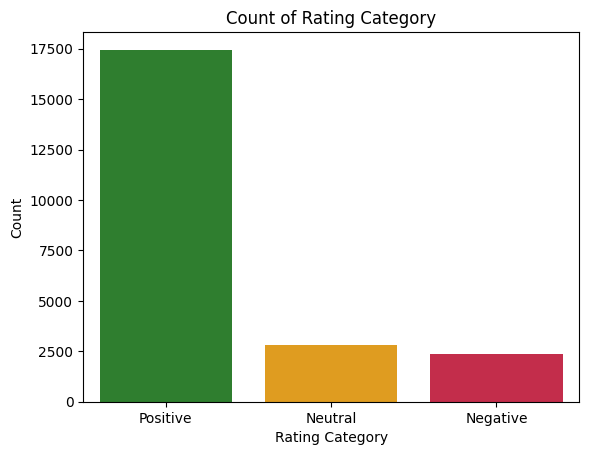

In [17]:
# plot Rating category
colors = ["forestgreen", "orange", "crimson"]
sns.countplot(x="Rating_Category", data=df, hue="Rating_Category", palette=colors, legend=False)
plt.title("Count of Rating Category")
plt.xlabel("Rating Category")
plt.ylabel("Count")
plt.show()

/tmp/ipykernel_4286/566475469.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Reds_r", ax=axes[i], order=df[col].value_counts().index)
/tmp/ipykernel_4286/566475469.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Reds_r", ax=axes[i], order=df[col].value_counts().index)
/tmp/ipykernel_4286/566475469.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Reds_r", ax=axes[i], order=df[col].value_counts().index)


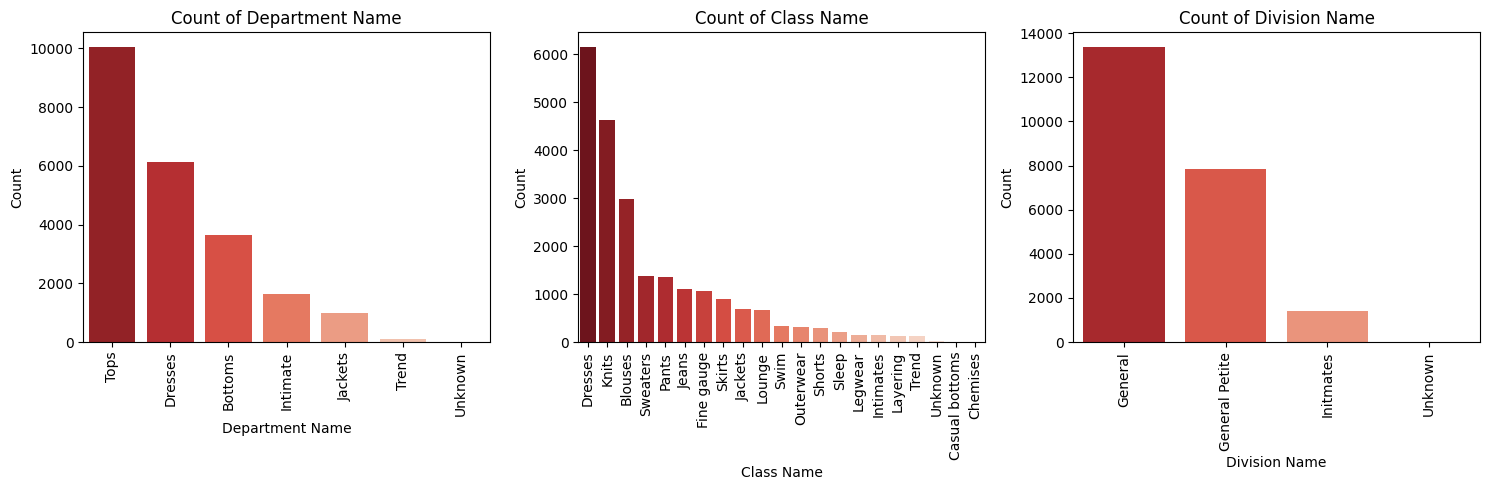

In [18]:
# Department Name, Class Name, Division Name count plot
cat_col = ["Department Name", "Class Name", "Division Name"]

# Subplot for all categories
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(cat_col):
    sns.countplot(x=col, data=df, palette="Reds_r", ax=axes[i], order=df[col].value_counts().index)
    axes[i].set_title(f"Count of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()


In [19]:
# Review text length analysis
df['Review_Length'] = df['Review Text'].apply(
    lambda x: len(str(x).split())
)

# Statistical summary
print(df['Review_Length'].describe())

count    22641.000000
mean        60.196679
std         28.534612
min          2.000000
25%         36.000000
50%         59.000000
75%         88.000000
max        115.000000
Name: Review_Length, dtype: float64


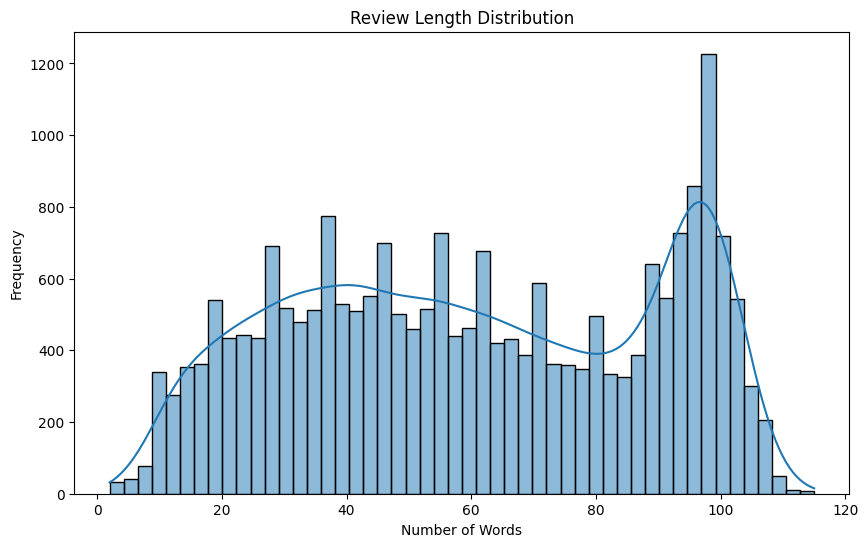

In [20]:
# Review length distribution
plt.figure(figsize=(10, 6))
sns.histplot(df['Review_Length'], bins=50, kde=True)
plt.title('Review Length Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

/tmp/ipykernel_4286/80545175.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Rating_Category', y='Review_Length', data=df, order=['Positive', 'Nutral', 'Negative'], palette=colors)


Text(0, 0.5, 'Review Length')

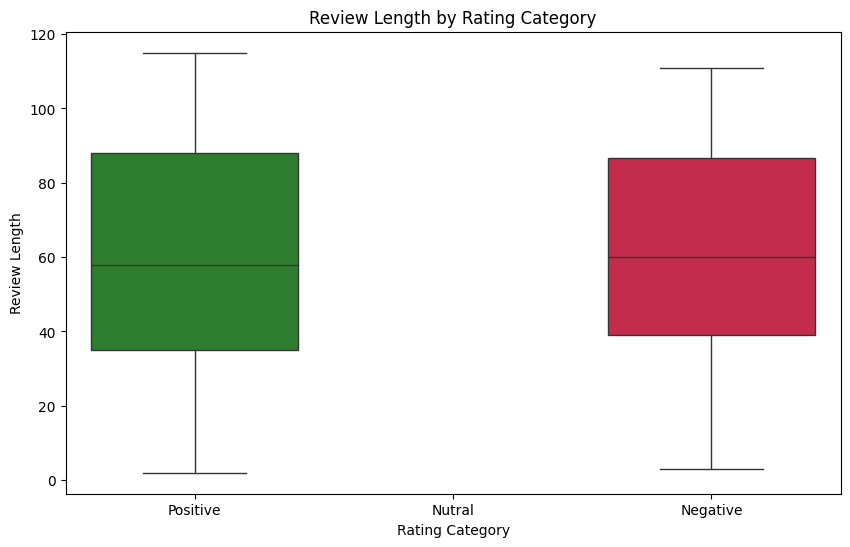

In [21]:
# Rating category wise review lenght
plt.figure(figsize=(10, 6))
colors = ["forestgreen", "orange", "crimson"]
sns.boxplot(x='Rating_Category', y='Review_Length', data=df, order=['Positive', 'Nutral', 'Negative'], palette=colors)
plt.title('Review Length by Rating Category')
plt.xlabel('Rating Category')
plt.ylabel('Review Length')

In [22]:
sentiment_length = df.groupby('Rating_Category')['Review_Length'].mean()

print(sentiment_length)

Rating_Category
Negative    60.870886
Neutral     64.218208
Positive    59.454436
Name: Review_Length, dtype: float64


### Review Length Analysis by Sentiment

The average review length was compared across the three sentiment categories. Neutral reviews had the highest average length of approximately 64.22 words, followed by Negative reviews with 60.87 words and Positive reviews with 59.45 words.

The results indicate a small difference in average review length across sentiment categories. However, review length alone may not be a reliable indicator of customer sentiment.

In [23]:
from collections import Counter
import re

# Combine all review text
all_text = ' '.join(df['Review Text'].astype(str))

# Convert to lowercase
all_text = all_text.lower()

# Extract words
words = re.findall(r'\b[a-z]+\b', all_text)

# Count word frequency
word_counts = Counter(words)

# Display top 20 words
print(word_counts.most_common(20))

[('the', 76166), ('i', 67070), ('it', 49284), ('and', 49009), ('a', 43018), ('is', 30641), ('this', 25762), ('to', 24583), ('in', 20723), ('but', 16556), ('on', 15328), ('for', 14000), ('of', 13429), ('with', 12803), ('was', 12221), ('so', 12023), ('my', 11028), ('dress', 10567), ('that', 10014), ('not', 9799)]


# Remove stopwords using NLTK

In [24]:
import nltk
from nltk.corpus import stopwords
from collections import Counter

nltk.download('stopwords')

# Load English stopwords
stop_words = set(stopwords.words('english'))

# Preserve important negation words
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

# Combine all reviews
all_text = ' '.join(df['Review Text'].astype(str))

# Convert to lowercase
all_text = all_text.lower()

# Extract words
words = re.findall(r'\b[a-z]+\b', all_text)

# Remove stopwords
filtered_words = [word for word in words if word not in stop_words]

# Count word frequency
word_counts = Counter(filtered_words)

# Display top 20 words
print(word_counts.most_common(20))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


[('dress', 10567), ('not', 9799), ('love', 8951), ('size', 8772), ('top', 7418), ('fit', 7325), ('like', 7149), ('wear', 6439), ('great', 6117), ('would', 5109), ('fabric', 4798), ('small', 4729), ('color', 4605), ('look', 4039), ('really', 3925), ('ordered', 3850), ('little', 3775), ('perfect', 3774), ('one', 3636), ('flattering', 3519)]


## Visualize the most frequent words
+ Generate WordCloud

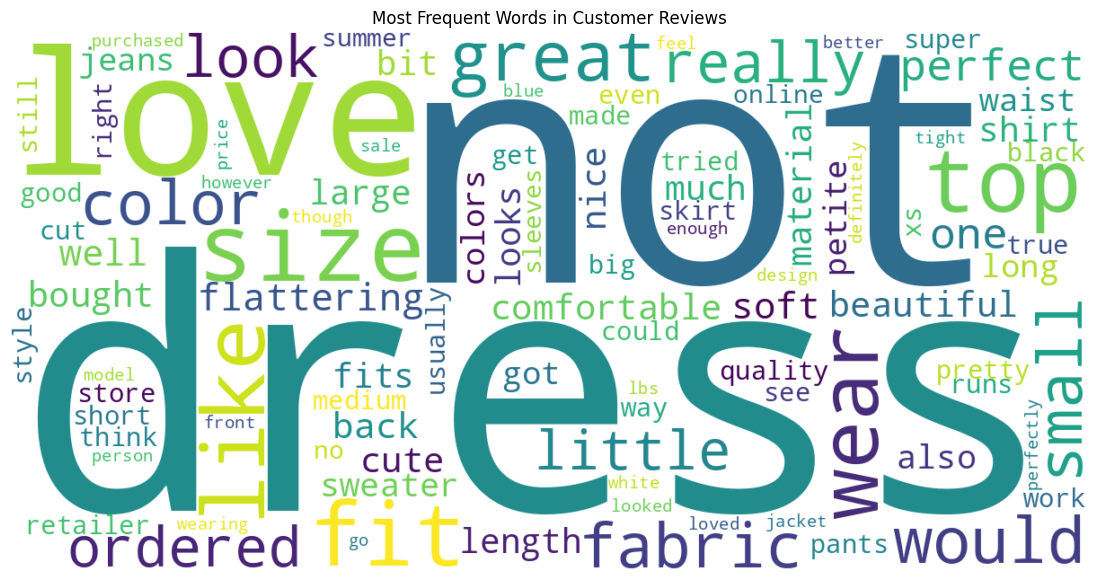

In [25]:
from wordcloud import WordCloud


# Generate WordCloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100
).generate_from_frequencies(word_counts)

# Display WordCloud
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Words in Customer Reviews')

plt.show()

# Separate Positive and Negative WordClouds

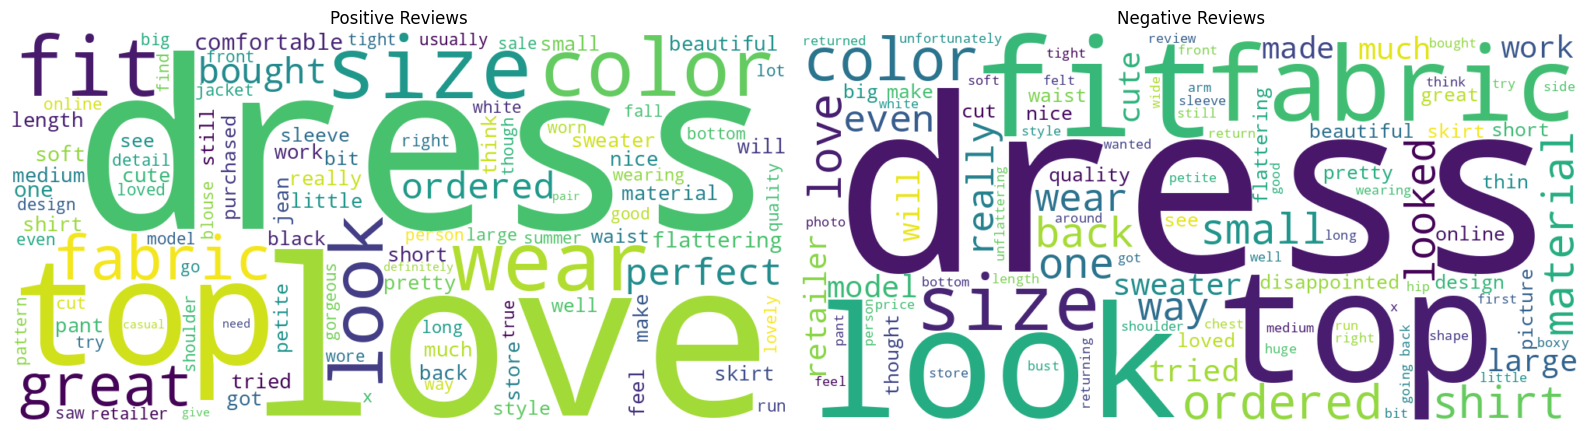

In [26]:
# Separate reviews
positive_text = ' '.join(
    df[df['Rating_Category'] == 'Positive']['Review Text'].astype(str)
)

negative_text = ' '.join(
    df[df['Rating_Category'] == 'Negative']['Review Text'].astype(str)
)

# Generate word clouds
positive_wc = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(positive_text)

negative_wc = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(negative_text)

# Plot
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(positive_wc, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Reviews')

plt.subplot(1, 2, 2)
plt.imshow(negative_wc, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Reviews')

plt.tight_layout()
plt.show()

### Word Frequency Analysis

The word frequency analysis revealed that terms such as "dress", "size", "fit", "fabric", and "top" occur frequently in customer reviews. These words indicate that customers commonly discuss product types, sizing, fitting, and material quality.

Words such as "love", "great", and "perfect" represent potentially positive expressions, while "not" is an important negation term that should be preserved during text preprocessing.

This analysis provides an initial understanding of customer vocabulary and helps identify useful textual features for sentiment classification.

## Sentiment distribution by department

In [27]:
department_sentiment = pd.crosstab(
    df['Department Name'],
    df['Rating_Category'],
    normalize='index'
) * 100

print(department_sentiment.round(2))

Rating_Category  Negative  Neutral  Positive
Department Name                             
Bottoms              8.66    11.11     80.23
Dresses             11.08    13.51     75.41
Intimate             8.89    10.71     80.40
Jackets             10.78     8.98     80.24
Tops                10.91    12.94     76.15
Trend               17.80    16.10     66.10
Unknown              0.00     0.00    100.00


## Visualize department-wise sentiment

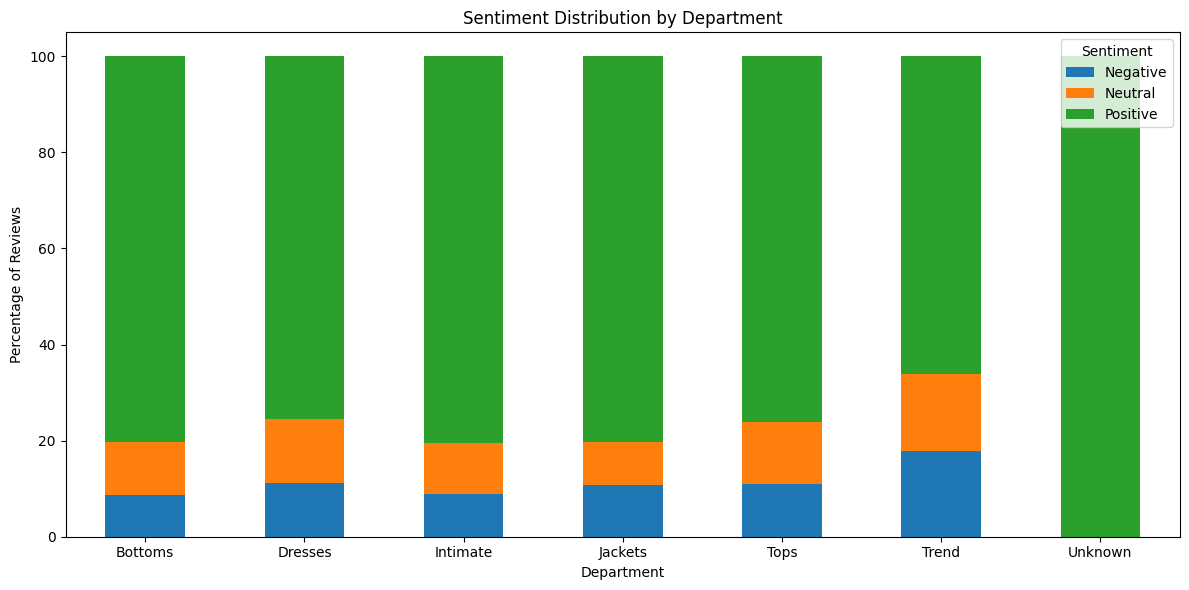

In [28]:
department_sentiment.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Sentiment Distribution by Department')
plt.xlabel('Department')
plt.ylabel('Percentage of Reviews')
plt.legend(title='Sentiment')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Identify departments with the highest negative sentiment

Department Name
Trend       17.80
Dresses     11.08
Tops        10.91
Jackets     10.78
Intimate     8.89
Bottoms      8.66
Unknown      0.00
Name: Rating_Category, dtype: float64


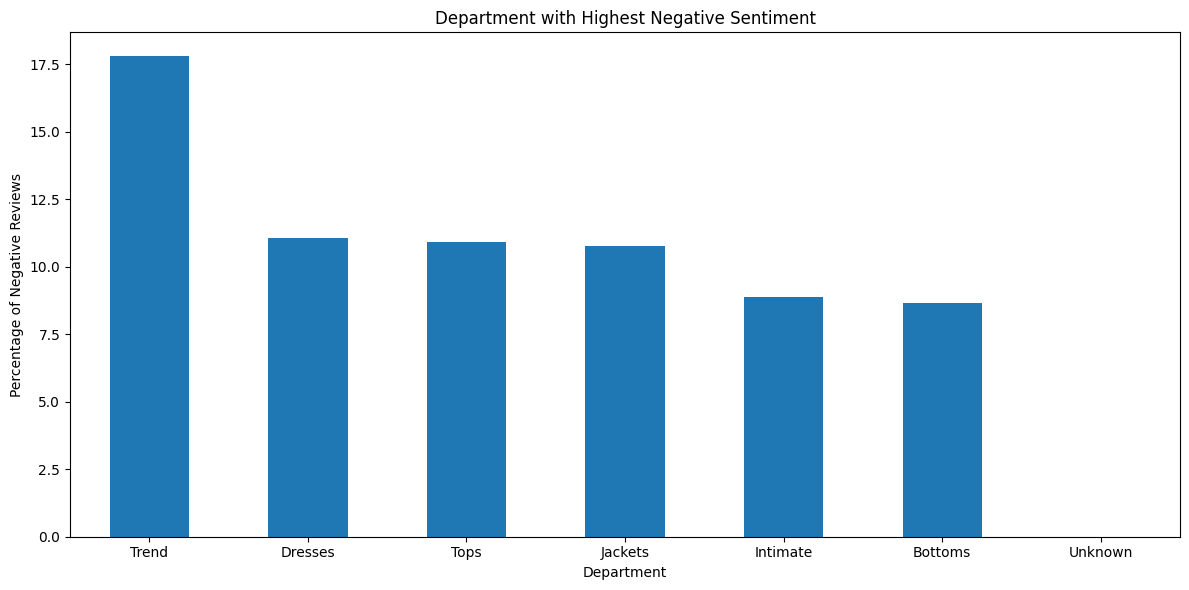

In [29]:
negative_by_department = (
    df.groupby('Department Name')['Rating_Category']
    .apply(lambda x: (x == 'Negative').mean() * 100)
    .sort_values(ascending=False)
)

print(negative_by_department.round(2))

negative_by_department.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Department with Highest Negative Sentiment')
plt.xlabel('Department')
plt.ylabel('Percentage of Negative Reviews')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

## Initialize stopwords and lemmatizer

In [31]:
stop_words = set(stopwords.words('english'))

# Preserve negation words because they affect sentiment
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

lemmatizer = WordNetLemmatizer()

## Create a text-cleaning function

In [32]:
def clean_text(text):
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Keep alphabetic characters and spaces
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal and lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return ' '.join(tokens)

## Apply preprocessing

In [33]:
nltk.download('punkt_tab')

df['Cleaned_Review'] = df['Review Text'].apply(clean_text)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


## Compare original and cleaned reviews

In [34]:
print("Original Review:")
print(df['Review Text'].iloc[0])

print("\nCleaned Review:")
print(df['Cleaned_Review'].iloc[0])

Original Review:
Absolutely wonderful - silky and sexy and comfortable

Cleaned Review:
absolutely wonderful silky sexy comfortable


In [35]:
X = df['Cleaned_Review']
y = df['Rating_Category']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (22641,)
Target shape: (22641,)


## Check class distribution

In [36]:
print(y.value_counts())
print("\nClass percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Rating_Category
Positive    17448
Neutral      2823
Negative     2370
Name: count, dtype: int64

Class percentages:
Rating_Category
Positive    77.06
Neutral     12.47
Negative    10.47
Name: proportion, dtype: float64


## Split the dataset

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (18112,)
Testing data: (4529,)


## Verify distribution after splitting

In [38]:
print("Training distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training distribution:
Rating_Category
Positive    0.771
Neutral     0.125
Negative    0.105
Name: proportion, dtype: float64

Testing distribution:
Rating_Category
Positive    0.771
Neutral     0.125
Negative    0.105
Name: proportion, dtype: float64


In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer


tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

## Fit on training data and transform both sets

In [40]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

## Check the output

In [41]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nTotal vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (18112, 10000)
Testing TF-IDF shape: (4529, 10000)

Total vocabulary size: 10000


## See the words learned by TF-IDF

In [42]:
feature_names = tfidf.get_feature_names_out()

print(feature_names[:30])

['aa' 'ability' 'able' 'able get' 'able go' 'able order' 'able pull'
 'able size' 'able try' 'able wear' 'absolute' 'absolutely'
 'absolutely adorable' 'absolutely adore' 'absolutely beautiful'
 'absolutely fell' 'absolutely gorgeous' 'absolutely love'
 'absolutely loved' 'absolutely no' 'absolutely not' 'absolutely perfect'
 'absolutely stunning' 'abt' 'accent' 'accentuate' 'accentuated'
 'accentuates' 'acceptable' 'accessorize']


Logistic Regression Results
--------------------------------
Accuracy: 0.784279090306911

Classification Report:
              precision    recall  f1-score   support

    Negative       0.48      0.63      0.54       474
     Neutral       0.34      0.45      0.39       565
    Positive       0.95      0.86      0.90      3490

    accuracy                           0.78      4529
   macro avg       0.59      0.65      0.61      4529
weighted avg       0.83      0.78      0.80      4529



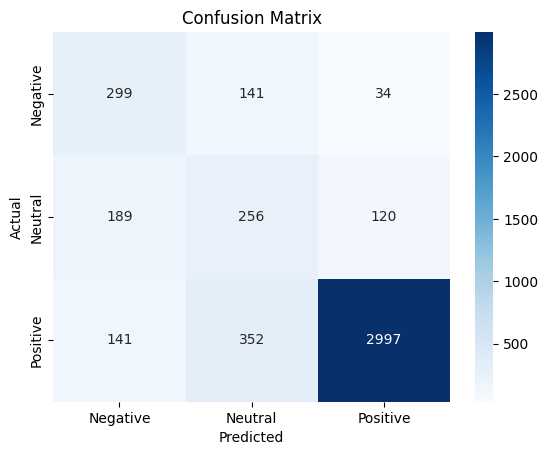

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize the model

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train the model

lr_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred = lr_model.predict(X_test_tfidf)

# Evaluate the model
print("Logistic Regression Results")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
labels_all = ['Negative', 'Neutral', 'Positive']
cm = confusion_matrix(y_test, y_pred, labels=labels_all)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_all, yticklabels=labels_all)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Naive Bayes Results
--------------------------------
Accuracy: 0.7860454846544491

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.12      0.21       474
     Neutral       0.41      0.04      0.08       565
    Positive       0.79      1.00      0.88      3490

    accuracy                           0.79      4529
   macro avg       0.64      0.39      0.39      4529
weighted avg       0.74      0.79      0.71      4529



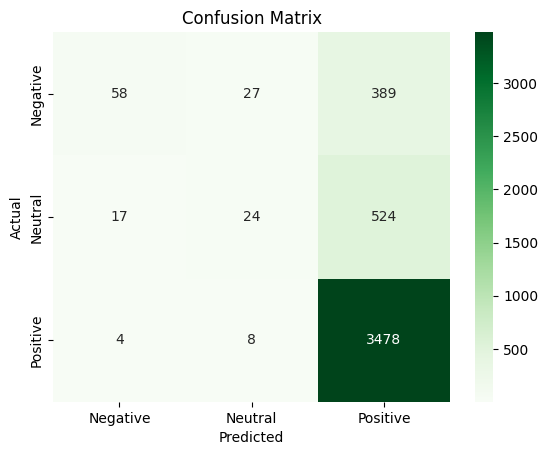

In [44]:
from sklearn.naive_bayes import MultinomialNB

# Initialize the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluate the model
print("Naive Bayes Results")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

# plot confusion mertix
cm = confusion_matrix(y_test, y_pred_nb, labels=labels_all)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels_all,
            yticklabels=labels_all)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


Support Vector Machine Results
--------------------------------
Accuracy: 0.8083462132921174

Classification Report:
              precision    recall  f1-score   support

    Negative       0.53      0.56      0.54       474
     Neutral       0.38      0.35      0.36       565
    Positive       0.91      0.92      0.91      3490

    accuracy                           0.81      4529
   macro avg       0.61      0.61      0.61      4529
weighted avg       0.81      0.81      0.81      4529



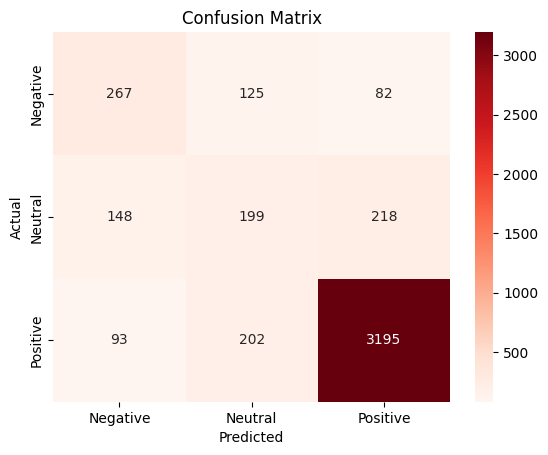

In [45]:
from sklearn.svm import LinearSVC

# Initilize the model
svm_model = LinearSVC(
    class_weight='balanced',
    random_state=42
)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test_tfidf)

# Evaluate the model
print("Support Vector Machine Results")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

# Plot confusion metrix
cm = confusion_matrix(y_test, y_pred_svm, labels=labels_all)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=labels_all,
            yticklabels=labels_all)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Compare all model

In [46]:
# compare all model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
model = {
    'Logistic Regression': y_pred,
    'Naive Bayes': y_pred_nb,
    'Support Vector Machine': y_pred_svm
}

results = []

for model_name, predictions in model.items():

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision (Macro)': precision_score(
            y_test, predictions, average='macro'
        ),
        'Recall (Macro)': recall_score(
            y_test, predictions, average='macro'
        ),
        'F1 Score (Macro)': f1_score(
            y_test, predictions, average='macro'
        )
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(2))

                    Model  Accuracy  Precision (Macro)  Recall (Macro)  \
0     Logistic Regression      0.78               0.59            0.65   
1             Naive Bayes      0.79               0.64            0.39   
2  Support Vector Machine      0.81               0.61            0.61   

   F1 Score (Macro)  
0              0.61  
1              0.39  
2              0.61  


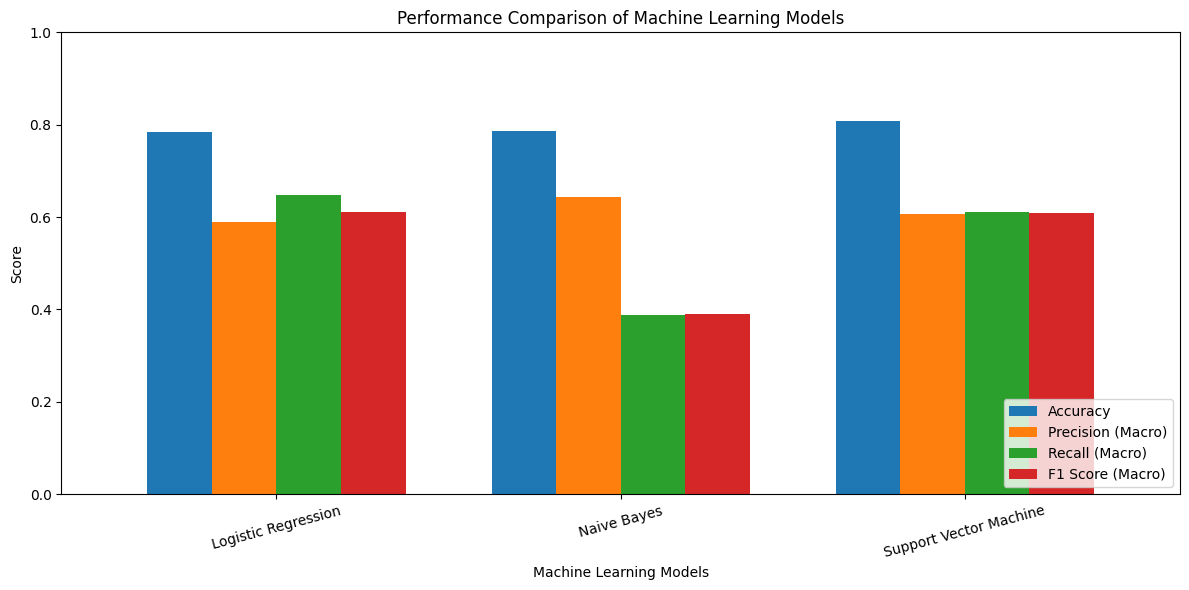

In [47]:
comparison_plot = comparison_df.set_index('Model')

comparison_plot.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.75
)

plt.title('Performance Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Compare confusion matrices

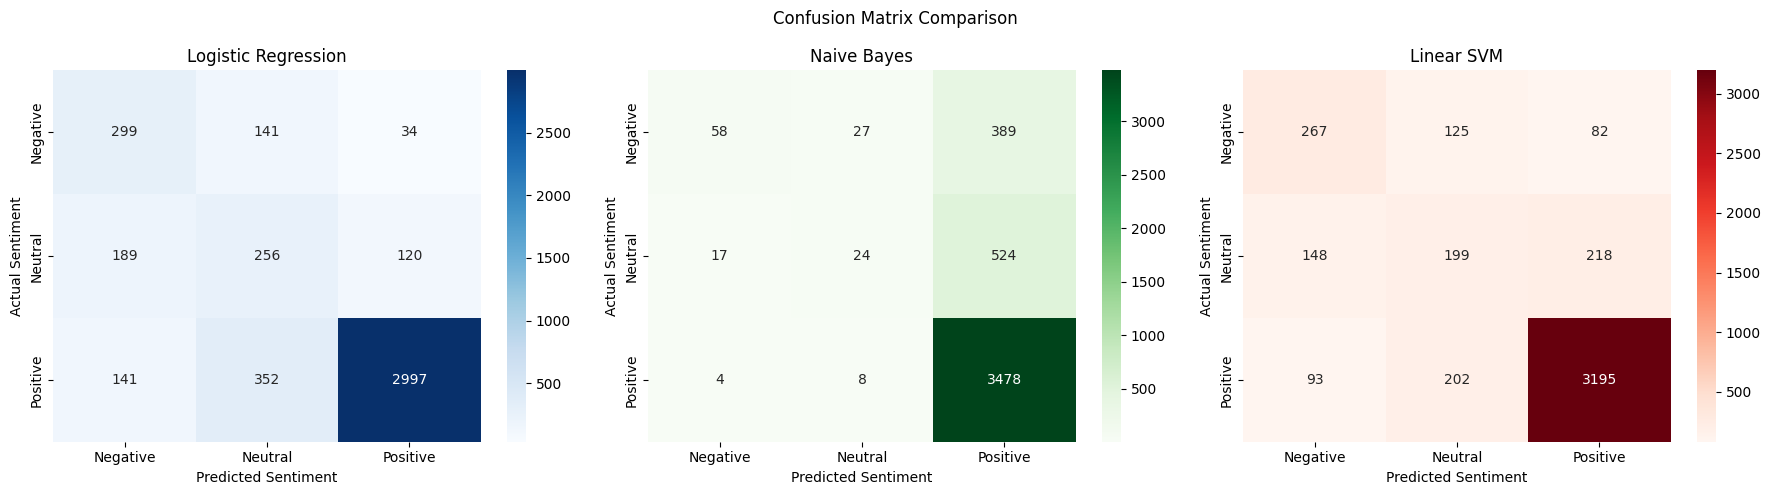

In [48]:
from sklearn.metrics import confusion_matrix

predictions_dict = {
    'Logistic Regression': y_pred,
    'Naive Bayes': y_pred_nb,
    'Linear SVM': y_pred_svm
}

labels = ['Negative', 'Neutral', 'Positive']
colors = ['Blues', 'Greens', 'Reds']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions), cmap_color in zip(
    axes, predictions_dict.items(), colors
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap=cmap_color,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Sentiment')
    ax.set_ylabel('Actual Sentiment')

plt.suptitle('Confusion Matrix Comparison')
plt.tight_layout()
plt.show()

## Identify the best model

In [50]:
predictions = {
    'Logistic Regression': y_pred,
    'Naive Bayes': y_pred_nb,
    'Linear SVM': y_pred_svm
}

results_df = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Macro F1': f1_score(y_test, pred, average='macro')
    }
    for name, pred in predictions.items()
])

results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)

display(results_df.style.format({'Accuracy': '{:.4f}', 'Macro F1': '{:.4f}'}))

best_model = results_df.iloc[0]

print("\nBest Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'] * 100, 2), "%")
print("Macro F1:", round(best_model['Macro F1'], 4))

,Model,Accuracy,Macro F1
0,Linear SVM,0.8083,0.6078
1,Naive Bayes,0.7860,0.3898
2,Logistic Regression,0.7843,0.6115



Best Model: Linear SVM
Accuracy: 80.83 %
Macro F1: 0.6078
